SESSÃO 08 — Preparação do conjunto de treinamento e implementação inicial de classificação supervisionada.

In [1]:

# SESSAO 08 - TAREFA 01
# Recuperacao e conferencia do protocolo V3

import pandas as pd

# 1. Carregar o manifesto oficial da V3
url = (
    "https://raw.githubusercontent.com/anacunh/"
    "3W-C1-AnaLaura/main/protocolo_v3/"
    "02_Instancias_Reais_V3.csv"
)

manifesto_v3 = pd.read_csv(url)

# 2. Conferir integridade da V3
assert len(manifesto_v3) == 1119
assert manifesto_v3["Poco"].nunique() == 40
assert manifesto_v3["Arquivo"].notna().all()

assert (
    manifesto_v3.groupby("Poco")["Conjunto"]
    .nunique() == 1
).all()

# 3. Separar SOMENTE os arquivos de treinamento
treino_v3 = manifesto_v3[
    manifesto_v3["Conjunto"] == "Treino"
].copy()

assert len(treino_v3) == 528
assert treino_v3["Poco"].nunique() == 28

# 4. Conferir os conjuntos
resumo = manifesto_v3.groupby("Conjunto").agg(
    Arquivos=("Arquivo", "count"),
    Pocos=("Poco", "nunique")
)

print("PROTOCOLO V3:")
display(resumo)

# 5. Distribuicao das categorias do treinamento
print("\nCATEGORIAS NO TREINAMENTO:")
display(
    treino_v3["Categoria"]
    .value_counts()
    .sort_index()
    .to_frame("Arquivos")
)

# 6. Conferir o arquivo usado na Sessao 07
arquivo_exemplo = (
    "WELL-00002_20131104004101.parquet"
)

print("\nARQUIVO DA SESSAO 07:")
display(
    treino_v3.loc[
        treino_v3["Arquivo"] == arquivo_exemplo,
        ["Arquivo", "Poco", "Categoria", "Conjunto"]
    ]
)

print("\nTAREFA 01 EXECUTADA")
print("V3 PRESERVADA - TREINAMENTO IDENTIFICADO")


PROTOCOLO V3:


,Arquivos,Pocos
Conjunto,,
Teste,408,6
Treino,528,28
Validacao,183,6



CATEGORIAS NO TREINAMENTO:


,Arquivos
Categoria,
0,268
1,1
2,18
3,31
4,143
5,6
6,3
7,6
8,10



ARQUIVO DA SESSAO 07:


,Arquivo,Poco,Categoria,Conjunto
408,WELL-00002_20131104004101.parquet,WELL-00002,2,Treino



TAREFA 01 EXECUTADA
V3 PRESERVADA - TREINAMENTO IDENTIFICADO


In [2]:

# SESSAO 08 - TAREFA 02
# Definicao inicial dos rotulos do C1

import io
import requests
import pandas as pd

# 1. Recuperar o exemplo do treinamento
arquivo = "WELL-00002_20131104004101.parquet"

url = (
    "https://raw.githubusercontent.com/petrobras/3W/"
    f"main/dataset/2/{arquivo}"
)

resposta = requests.get(url, timeout=60)
resposta.raise_for_status()

df_exemplo = pd.read_parquet(
    io.BytesIO(resposta.content)
)

# 2. Preservar os rotulos originais
rotulo_original = pd.to_numeric(
    df_exemplo["class"], errors="coerce"
).astype("Int64")

# 3. Criar os rotulos para o modelo
rotulo_c1 = rotulo_original.copy()

transientes = rotulo_original.between(
    101, 109
).fillna(False)

rotulo_c1.loc[transientes] = (
    rotulo_original.loc[transientes] - 100
)

# Manter apenas classes de 0 a 9
rotulo_c1 = rotulo_c1.where(
    rotulo_c1.isin(range(10))
)

# 4. Identificar a fase original
fase = pd.Series(
    "Sem rotulo", index=df_exemplo.index
)

fase.loc[rotulo_original.eq(0).fillna(False)] = (
    "Normal"
)

fase.loc[rotulo_original.between(
    1, 9
).fillna(False)] = "Evento"

fase.loc[transientes] = "Transiente"

# 5. Organizar e conferir
tabela_rotulos = pd.DataFrame({
    "Rotulo_original": rotulo_original,
    "Rotulo_C1": rotulo_c1,
    "Fase": fase
})

print("MAPEAMENTO DOS ROTULOS:")
display(
    tabela_rotulos.groupby(
        ["Rotulo_original", "Rotulo_C1", "Fase"],
        dropna=False
    ).size().reset_index(name="Registros")
)

print("\nROTULOS PARA O MODELO:")
display(
    rotulo_c1.value_counts(dropna=False)
    .sort_index()
    .to_frame("Registros")
)

print("\nTAREFA 02 EXECUTADA")


MAPEAMENTO DOS ROTULOS:


,Rotulo_original,Rotulo_C1,Fase,Registros
0,0,0,Normal,3755
1,2,2,Evento,217
2,102,2,Transiente,5149
3,<NA>,<NA>,Sem rotulo,3600



ROTULOS PARA O MODELO:


,Registros
class,
0,3755
2,5366
<NA>,3600



TAREFA 02 EXECUTADA


In [3]:

# SESSAO 08 - TAREFA 03
# Teste-piloto de janelas em diferentes categorias

import io
import time
import requests
import numpy as np
import pandas as pd

sensores = ["P-TPT", "T-TPT", "P-ANULAR"]
tamanho, passo = 100, 50

# Um arquivo de treinamento por categoria
amostra = (
    treino_v3.sort_values(["Categoria", "Arquivo"])
    .groupby("Categoria")
    .head(1)
)

resumos = []
janelas_piloto = []

with requests.Session() as sessao:

    for item in amostra.itertuples(index=False):

        url = (
            "https://raw.githubusercontent.com/petrobras/3W/"
            f"main/dataset/{item.Categoria}/{item.Arquivo}"
        )

        try:
            for tentativa in range(3):
                try:
                    resposta = sessao.get(url, timeout=60)
                    resposta.raise_for_status()
                    dados = pd.read_parquet(
                        io.BytesIO(resposta.content)
                    )
                    break
                except Exception:
                    if tentativa == 2:
                        raise
                    time.sleep(2 ** tentativa)

            if not set(sensores).issubset(dados.columns):
                raise ValueError("Sensor nao encontrado")

            if not isinstance(dados.index, pd.DatetimeIndex):
                raise ValueError("Indice temporal nao reconhecido")

            rotulos = pd.to_numeric(
                dados["class"], errors="coerce"
            )

            medidas = dados[sensores].apply(
                pd.to_numeric, errors="coerce"
            ).to_numpy()

            delta = (
                dados.index.to_series()
                .diff().dt.total_seconds()
                .to_numpy()
            )

            contagem = {
                "Arquivo": item.Arquivo,
                "Categoria": item.Categoria,
                "Validas": 0,
                "Sem_rotulo": 0,
                "Rotulo_misto": 0,
                "Sensor_invalido": 0,
                "Tempo_irregular": 0,
                "Outro_rotulo": 0
            }

            for inicio in range(
                0, len(dados) - tamanho + 1, passo
            ):

                fim = inicio + tamanho
                trecho_rotulos = rotulos.iloc[inicio:fim]

                if trecho_rotulos.isna().any():
                    contagem["Sem_rotulo"] += 1
                    continue

                if trecho_rotulos.nunique() != 1:
                    contagem["Rotulo_misto"] += 1
                    continue

                rotulo = int(trecho_rotulos.iloc[0])

                if rotulo not in list(range(10)) + list(range(101, 110)):
                    contagem["Outro_rotulo"] += 1
                    continue

                intervalos = delta[inicio + 1:fim]

                if not np.allclose(intervalos, 1, atol=0.1):
                    contagem["Tempo_irregular"] += 1
                    continue

                if not np.isfinite(medidas[inicio:fim]).all():
                    contagem["Sensor_invalido"] += 1
                    continue

                rotulo_c1 = (
                    rotulo - 100 if rotulo >= 101
                    else rotulo
                )

                janelas_piloto.append({
                    "Arquivo": item.Arquivo,
                    "Poco": item.Poco,
                    "Categoria": item.Categoria,
                    "Inicio": inicio,
                    "Fim": fim - 1,
                    "Rotulo_original": rotulo,
                    "Rotulo_C1": rotulo_c1
                })

                contagem["Validas"] += 1

            resumos.append(contagem)

        except Exception as erro:
            print("FALHA:", item.Arquivo, str(erro))
            resumos.append({
                "Arquivo": item.Arquivo,
                "Categoria": item.Categoria,
                "Erro": str(erro)
            })

resumo_piloto = pd.DataFrame(resumos)
tabela_piloto = pd.DataFrame(janelas_piloto)

print("DIAGNOSTICO POR ARQUIVO:")
display(resumo_piloto)

print("\nJANELAS VALIDAS POR ROTULO C1:")
if not tabela_piloto.empty:
    display(
        tabela_piloto["Rotulo_C1"]
        .value_counts()
        .sort_index()
        .to_frame("Janelas")
    )

print("\nARQUIVOS ANALISADOS:", len(resumo_piloto))
print("JANELAS VALIDAS:", len(tabela_piloto))

resumo_piloto.to_csv(
    "08_Resumo_Piloto_V3.csv", index=False
)

tabela_piloto.to_csv(
    "08_Janelas_Piloto_V3.csv", index=False
)

print("\nTAREFA 03 EXECUTADA")


DIAGNOSTICO POR ARQUIVO:


,Arquivo,Categoria,Validas,Sem_rotulo,Rotulo_misto,Sensor_invalido,Tempo_irregular,Outro_rotulo
0,WELL-00002_20131211220015.parquet,0,142,72,0,0,0,0
1,WELL-00002_20140126180030.parquet,1,282,72,4,0,0,0
2,WELL-00002_20131104004101.parquet,2,177,72,4,0,0,0
3,WELL-00014_20170917140000.parquet,3,351,72,0,3,0,0
4,WELL-00002_20131208220000.parquet,4,142,72,0,0,0,0
5,WELL-00020_20140314144539.parquet,5,2908,72,4,24,0,0
6,WELL-00002_20140212160333.parquet,6,482,72,4,0,0,0
7,WELL-00021_20180611011218.parquet,7,854,72,4,0,0,0
8,WELL-00025_20200629194141.parquet,8,14366,72,4,0,0,0
9,WELL-00014_20160304155906.parquet,9,1343,72,2,0,0,0



JANELAS VALIDAS POR ROTULO C1:


,Janelas
Rotulo_C1,
0,3183
1,188
2,103
3,351
4,142
5,2759
6,183
7,505
8,12652



ARQUIVOS ANALISADOS: 10
JANELAS VALIDAS: 21047

TAREFA 03 EXECUTADA


In [4]:

# SESSAO 08 - TAREFA 04
# Extracao de atributos por janela - treinamento V3

import io
import time
import requests
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter
from scipy.stats import skew, kurtosis
from numpy.lib.stride_tricks import sliding_window_view
from tqdm.auto import tqdm
from google.colab import drive

# 1. Pasta de resultados permanentes
drive.mount("/content/drive")

pasta = Path(
    "/content/drive/MyDrive/C1_SESSAO08_ATRIBUTOS"
)
pasta.mkdir(parents=True, exist_ok=True)

# 2. Configuracoes do experimento
sensores = ["P-TPT", "T-TPT", "P-ANULAR"]
tamanho = 100
passo = 50
codigos = list(range(10)) + list(range(101, 110))

falhas = []
contagem_classes = Counter()

# 3. Processar apenas os arquivos do treino
with requests.Session() as sessao:

    for item in tqdm(
        treino_v3.itertuples(index=False),
        total=len(treino_v3)
    ):

        destino = pasta / (
            Path(item.Arquivo).stem + "_atributos.parquet"
        )

        # Pular arquivos ja processados
        if destino.exists():
            try:
                anterior = pd.read_parquet(
                    destino, columns=["Rotulo_C1"]
                )
                contagem_classes.update(
                    anterior["Rotulo_C1"].value_counts().to_dict()
                )
                continue
            except Exception:
                destino.unlink()

        try:
            url = (
                "https://raw.githubusercontent.com/petrobras/3W/"
                f"main/dataset/{item.Categoria}/{item.Arquivo}"
            )

            # Download com novas tentativas
            for tentativa in range(3):
                try:
                    resposta = sessao.get(url, timeout=60)
                    resposta.raise_for_status()

                    if resposta.content[:4] != b"PAR1":
                        raise ValueError("Parquet invalido")

                    dados = pd.read_parquet(
                        io.BytesIO(resposta.content)
                    )
                    break
                except Exception:
                    if tentativa == 2:
                        raise
                    time.sleep(2 ** (tentativa + 1))

            if not isinstance(dados.index, pd.DatetimeIndex):
                raise ValueError("Indice temporal invalido")

            if not set(sensores + ["class"]).issubset(dados.columns):
                raise ValueError("Variavel necessaria ausente")

            if len(dados) < tamanho:
                raise ValueError("Arquivo menor que a janela")

            rotulos = pd.to_numeric(
                dados["class"], errors="coerce"
            ).to_numpy(dtype=float, na_value=np.nan)

            sinais = dados[sensores].apply(
                pd.to_numeric, errors="coerce"
            ).to_numpy(dtype=float)

            inicios = np.arange(
                0, len(dados) - tamanho + 1, passo
            )

            # Janelas com um unico rotulo original
            blocos_rotulos = sliding_window_view(
                rotulos, tamanho
            )[inicios]

            rotulos_ok = (
                np.isfinite(blocos_rotulos).all(axis=1)
                & (blocos_rotulos == blocos_rotulos[:, :1]).all(axis=1)
                & np.isin(blocos_rotulos[:, 0], codigos)
            )

            # Conferir intervalos de 1 segundo
            deltas = np.diff(
                dados.index.asi8
            ).astype(float) / 1e9

            blocos_tempo = sliding_window_view(
                deltas, tamanho - 1
            )[inicios]

            tempo_ok = np.isclose(
                blocos_tempo, 1, atol=0.1
            ).all(axis=1)

            inicios = inicios[rotulos_ok & tempo_ok]

            # Conferir as medicoes dos tres sensores
            blocos_sinais = sliding_window_view(
                sinais, tamanho, axis=0
            )[inicios]

            sinais_ok = np.isfinite(
                blocos_sinais
            ).all(axis=(1, 2))

            inicios = inicios[sinais_ok]
            blocos_sinais = blocos_sinais[sinais_ok]

            originais = rotulos[inicios].astype(int)

            rotulos_c1 = np.where(
                originais >= 101,
                originais - 100,
                originais
            )

            fases = np.where(
                originais == 0, "Normal",
                np.where(
                    originais >= 101, "Transiente", "Evento"
                )
            )

            resultado = pd.DataFrame({
                "Arquivo": [item.Arquivo] * len(inicios),
                "Poco": [item.Poco] * len(inicios),
                "Categoria": [item.Categoria] * len(inicios),
                "Inicio": inicios,
                "Fim": inicios + tamanho - 1,
                "Rotulo_original": originais,
                "Rotulo_C1": rotulos_c1,
                "Fase": fases
            })

            # Extrair os 27 atributos
            for i, sensor in enumerate(sensores):

                if len(inicios) == 0:
                    continue

                x = blocos_sinais[:, i, :]
                quantis = np.quantile(
                    x, [0.25, 0.50, 0.75], axis=1
                )

                resultado[f"{sensor}_media"] = x.mean(axis=1)
                resultado[f"{sensor}_desvio"] = x.std(
                    axis=1, ddof=1
                )
                resultado[f"{sensor}_minimo"] = x.min(axis=1)
                resultado[f"{sensor}_q25"] = quantis[0]
                resultado[f"{sensor}_mediana"] = quantis[1]
                resultado[f"{sensor}_q75"] = quantis[2]
                resultado[f"{sensor}_maximo"] = x.max(axis=1)

                variaveis = np.ptp(x, axis=1) > 1e-9

                assimetria = np.full(len(x), np.nan)
                curtose = np.full(len(x), np.nan)

                if variaveis.any():
                    assimetria[variaveis] = skew(
                        x[variaveis], axis=1
                    )
                    curtose[variaveis] = kurtosis(
                        x[variaveis], axis=1
                    )

                resultado[f"{sensor}_assimetria"] = assimetria
                resultado[f"{sensor}_curtose"] = curtose

            # Salvar sem depender da memoria do Colab
            temporario = destino.with_suffix(".partial")
            resultado.to_parquet(temporario, index=False)
            temporario.replace(destino)

            contagem_classes.update(
                resultado["Rotulo_C1"].value_counts().to_dict()
            )

        except Exception as erro:
            falhas.append({
                "Arquivo": item.Arquivo,
                "Erro": str(erro)
            })

# 4. Diagnostico final
arquivos_salvos = len(
    list(pasta.glob("*_atributos.parquet"))
)

print("ARQUIVOS SALVOS:", arquivos_salvos)
print("FALHAS:", len(falhas))
print("JANELAS VALIDAS:", sum(contagem_classes.values()))

print("\nJANELAS POR ROTULO C1:")
display(
    pd.Series(
        dict(sorted(contagem_classes.items())),
        name="Janelas"
    ).to_frame()
)

if falhas:
    print("\nARQUIVOS COM FALHA:")
    display(pd.DataFrame(falhas))

    pd.DataFrame(falhas).to_csv(
        pasta / "08_Falhas_Processamento.csv",
        index=False
    )

print("\nTAREFA 04 EXECUTADA")
print("RESULTADOS SALVOS NO GOOGLE DRIVE")


Mounted at /content/drive


  0%|          | 0/528 [00:00<?, ?it/s]

ARQUIVOS SALVOS: 528
FALHAS: 0
JANELAS VALIDAS: 162326

JANELAS POR ROTULO C1:


,Janelas
0,102708
1,188
2,1700
3,10956
4,18793
5,6104
6,335
7,864
8,16904
9,3774



TAREFA 04 EXECUTADA
RESULTADOS SALVOS NO GOOGLE DRIVE


In [5]:

# SESSAO 08 - TAREFA 05
# Construir e auditar a matriz de treinamento

from pathlib import Path
import numpy as np
import pandas as pd

# 1. Localizar os arquivos salvos na Tarefa 04
pasta = Path(
    "/content/drive/MyDrive/C1_SESSAO08_ATRIBUTOS"
)

arquivos = sorted(
    pasta.glob("*_atributos.parquet")
)

print("ARQUIVOS ENCONTRADOS:", len(arquivos))

assert len(arquivos) == 528, (
    "Quantidade diferente dos 528 arquivos esperados."
)

# 2. Reunir as tabelas
tabelas = [pd.read_parquet(a) for a in arquivos]

matriz_treino = pd.concat(
    tabelas, ignore_index=True
)

# 3. Separar metadados dos atributos
metadados = [
    "Arquivo", "Poco", "Categoria",
    "Inicio", "Fim", "Rotulo_original",
    "Rotulo_C1", "Fase"
]

atributos = [
    coluna for coluna in matriz_treino.columns
    if coluna not in metadados
]

print("\nDIMENSOES DA MATRIZ:")
print("Janelas:", len(matriz_treino))
print("Atributos:", len(atributos))

assert len(matriz_treino) == 162326
assert len(atributos) == 27

# 4. Confirmar que os arquivos pertencem ao treino V3
arquivos_treino = set(treino_v3["Arquivo"])

assert set(
    matriz_treino["Arquivo"]
).issubset(arquivos_treino)

# Conferir os identificadores e categorias
referencia = treino_v3.set_index("Arquivo")

for coluna in ["Poco", "Categoria"]:
    esperado = matriz_treino["Arquivo"].map(
        referencia[coluna]
    )

    assert (
        matriz_treino[coluna].to_numpy()
        == esperado.to_numpy()
    ).all()

assert matriz_treino["Rotulo_C1"].between(0, 9).all()

# 5. Avaliar os valores ausentes
faltantes = (
    matriz_treino[atributos]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nATRIBUTOS COM VALORES AUSENTES:")
display(
    faltantes[faltantes > 0]
    .to_frame("Ausentes")
)

# 6. Verificar valores infinitos
infinitos = np.isinf(
    matriz_treino[atributos].to_numpy(dtype=float)
).sum()

print("\nVALORES INFINITOS:", int(infinitos))

# 7. Conferir a representatividade por classe
resumo_classes = (
    matriz_treino.groupby("Rotulo_C1")
    .agg(
        Janelas=("Arquivo", "size"),
        Arquivos=("Arquivo", "nunique"),
        Pocos=("Poco", "nunique")
    )
)

resumo_classes["Percentual"] = (
    100 * resumo_classes["Janelas"]
    / len(matriz_treino)
).round(2)

print("\nRESUMO POR CLASSE:")
display(resumo_classes)

# 8. Salvar a matriz completa no Drive
destino = pasta / "08_Matriz_Treinamento_C1.parquet"

matriz_treino.to_parquet(
    destino, index=False
)

resumo_classes.to_csv(
    pasta / "08_Resumo_Classes_Treinamento.csv"
)

print("\nMATRIZ SALVA:", destino.name)
print("TAREFA 05 EXECUTADA")


ARQUIVOS ENCONTRADOS: 528

DIMENSOES DA MATRIZ:
Janelas: 162326
Atributos: 27

ATRIBUTOS COM VALORES AUSENTES:


,Ausentes
P-ANULAR_curtose,46567
P-ANULAR_assimetria,46567
P-TPT_curtose,31939
P-TPT_assimetria,31939
T-TPT_curtose,23530
T-TPT_assimetria,23530



VALORES INFINITOS: 0

RESUMO POR CLASSE:


,Janelas,Arquivos,Pocos,Percentual
Rotulo_C1,,,,
0,102708,263,15,63.27
1,188,1,1,0.12
2,1700,18,5,1.05
3,10956,31,1,6.75
4,18793,133,2,11.58
5,6104,6,1,3.76
6,335,3,1,0.21
7,864,2,1,0.53
8,16904,3,3,10.41



MATRIZ SALVA: 08_Matriz_Treinamento_C1.parquet
TAREFA 05 EXECUTADA


DIVISAO INTERNA:
Pocos de treinamento: 12
Pocos de validacao: 3
Janelas de treinamento: 161385
Janelas de validacao: 941

CLASSES POR SUBCONJUNTO:


,Treino,Validacao
Rotulo_C1,,
0,102213,495
1,188,0
2,1512,188
3,10956,0
4,18793,0
5,6104,0
6,335,0
7,864,0
8,16904,0



INICIANDO TREINAMENTO...

RESULTADO PRELIMINAR:
F1 macro das classes presentes: 0.5897
Classes presentes na validacao: [np.int64(0), np.int64(2), np.int64(9)]
Classes ausentes na validacao: [1, 3, 4, 5, 6, 7, 8]

METRICAS POR CLASSE:


,precision,recall,f1-score,support
0,0.654,1.000,0.791,495.0
2,1.000,0.957,0.978,188.0
9,0.000,0.000,0.000,258.0


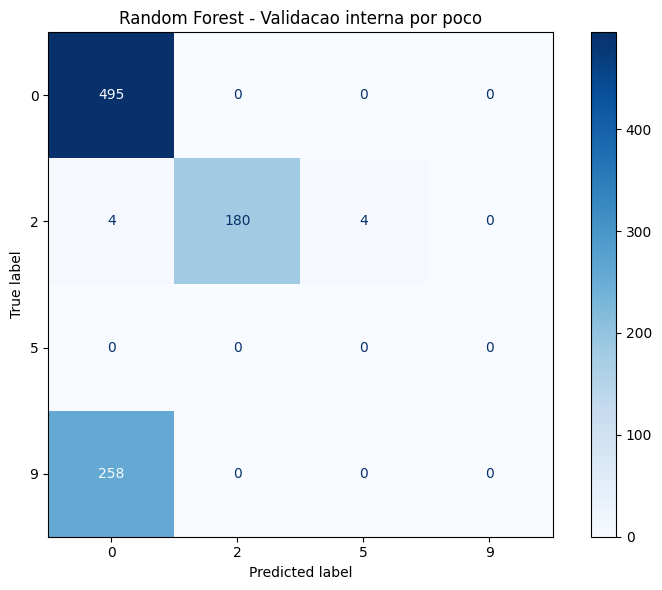


TAREFA 06 EXECUTADA
MODELO E RESULTADOS SALVOS NO DRIVE


In [6]:

# SESSAO 08 - TAREFA 06
# Primeiro Random Forest supervisionado
# Avaliacao preliminar por pocos independentes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score, classification_report,
    ConfusionMatrixDisplay
)

# 1. Preparar entradas, rotulos e pocos
X = matriz_treino[atributos]
y = matriz_treino["Rotulo_C1"].astype(int)
grupos = matriz_treino["Poco"]

# 2. Procurar uma divisao interna por poco
# que mantenha as dez classes no treinamento
divisor = GroupShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=42
)

escolha = None

for idx_treino, idx_val in divisor.split(X, y, grupos):

    classes_treino = set(y.iloc[idx_treino])
    classes_val = set(y.iloc[idx_val])

    if (
        classes_treino == set(range(10))
        and len(classes_val) >= 3
    ):
        escolha = (idx_treino, idx_val)
        break

if escolha is None:
    raise RuntimeError(
        "Nao foi encontrada divisao interna adequada."
    )

idx_treino, idx_val = escolha

X_treino = X.iloc[idx_treino]
X_val = X.iloc[idx_val]
y_treino = y.iloc[idx_treino]
y_val = y.iloc[idx_val]

pocos_treino = set(grupos.iloc[idx_treino])
pocos_val = set(grupos.iloc[idx_val])

assert pocos_treino.isdisjoint(pocos_val)

print("DIVISAO INTERNA:")
print("Pocos de treinamento:", len(pocos_treino))
print("Pocos de validacao:", len(pocos_val))
print("Janelas de treinamento:", len(X_treino))
print("Janelas de validacao:", len(X_val))

print("\nCLASSES POR SUBCONJUNTO:")
display(
    pd.DataFrame({
        "Treino": y_treino.value_counts(),
        "Validacao": y_val.value_counts()
    }).fillna(0).astype(int)
    .reindex(range(10), fill_value=0)
)

# 3. Criar pipeline
# Mediana ajustada somente no treino interno
modelo = Pipeline([
    ("imputacao", SimpleImputer(
        strategy="median"
    )),
    ("classificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# 4. Treinar o modelo
print("\nINICIANDO TREINAMENTO...")
modelo.fit(X_treino, y_treino)

# 5. Prever em pocos nao utilizados no ajuste
previsoes = modelo.predict(X_val)

classes_avaliadas = sorted(y_val.unique())

f1_macro = f1_score(
    y_val,
    previsoes,
    labels=classes_avaliadas,
    average="macro",
    zero_division=0
)

print("\nRESULTADO PRELIMINAR:")
print(f"F1 macro das classes presentes: {f1_macro:.4f}")
print("Classes presentes na validacao:", classes_avaliadas)
print(
    "Classes ausentes na validacao:",
    sorted(set(range(10)) - set(classes_avaliadas))
)

# 6. Metricas por classe presente
relatorio = classification_report(
    y_val,
    previsoes,
    labels=classes_avaliadas,
    output_dict=True,
    zero_division=0
)

metricas = pd.DataFrame(relatorio).T

print("\nMETRICAS POR CLASSE:")
display(
    metricas.loc[
        [str(c) for c in classes_avaliadas],
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

# 7. Matriz de confusao
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    previsoes,
    labels=sorted(set(y_val) | set(previsoes)),
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Random Forest - Validacao interna por poco")
plt.tight_layout()
plt.show()

# 8. Salvar resultados e divisao utilizada
predicoes = matriz_treino.iloc[idx_val][
    ["Arquivo", "Poco", "Rotulo_original",
     "Rotulo_C1", "Fase"]
].copy()

predicoes["Predicao_RF"] = previsoes

pd.DataFrame({
    "Poco": sorted(pocos_treino | pocos_val),
    "Subconjunto": [
        "Treino" if poco in pocos_treino
        else "Validacao"
        for poco in sorted(pocos_treino | pocos_val)
    ]
}).to_csv(
    pasta / "08_Divisao_Interna_RF.csv",
    index=False
)

predicoes.to_parquet(
    pasta / "08_Predicoes_RF_Preliminar.parquet",
    index=False
)

metricas.to_csv(
    pasta / "08_Metricas_RF_Preliminar.csv"
)

joblib.dump(
    modelo,
    pasta / "08_Modelo_RF_Preliminar.joblib"
)

print("\nTAREFA 06 EXECUTADA")
print("MODELO E RESULTADOS SALVOS NO DRIVE")


In [7]:

# SESSAO 08 - CONFERENCIA FINAL
# Representatividade dos pocos no primeiro Random Forest

import pandas as pd

# 1. Comparar pocos da V3 com os pocos da matriz
pocos_v3 = set(treino_v3["Poco"].unique())
pocos_matriz = set(matriz_treino["Poco"].unique())

sem_janelas = sorted(pocos_v3 - pocos_matriz)

print("POCOS NO TREINAMENTO V3:", len(pocos_v3))
print("POCOS COM JANELAS VALIDAS:", len(pocos_matriz))
print("POCOS SEM JANELAS VALIDAS:", len(sem_janelas))

print("\nPOCOS QUE NAO CONTRIBUIRAM:")
print(sem_janelas)

# 2. Distribuicao da validacao interna por poco
print("\nCLASSES REAIS POR POCO NA VALIDACAO:")
display(
    pd.crosstab(
        predicoes["Poco"],
        predicoes["Rotulo_C1"]
    )
)

# 3. Classes previstas por poco
print("\nCLASSES PREVISTAS POR POCO:")
display(
    pd.crosstab(
        predicoes["Poco"],
        predicoes["Predicao_RF"]
    )
)

# 4. Quantidade de arquivos e janelas por poco
resumo_pocos = matriz_treino.groupby("Poco").agg(
    Arquivos=("Arquivo", "nunique"),
    Janelas=("Arquivo", "size")
).sort_values("Janelas", ascending=False)

print("\nCONTRIBUICAO DOS POCOS:")
display(resumo_pocos)

resumo_pocos.to_csv(
    pasta / "08_Resumo_Pocos_Com_Janelas.csv"
)

print("\nCONFERENCIA FINAL EXECUTADA")


POCOS NO TREINAMENTO V3: 28
POCOS COM JANELAS VALIDAS: 15
POCOS SEM JANELAS VALIDAS: 13

POCOS QUE NAO CONTRIBUIRAM:
['WELL-00007', 'WELL-00008', 'WELL-00023', 'WELL-00026', 'WELL-00027', 'WELL-00028', 'WELL-00031', 'WELL-00032', 'WELL-00034', 'WELL-00035', 'WELL-00036', 'WELL-00037', 'WELL-00038']

CLASSES REAIS POR POCO NA VALIDACAO:


Rotulo_C1,0,2,9
Poco,,,
WELL-00009,69,60,0
WELL-00013,71,128,0
WELL-00040,355,0,258



CLASSES PREVISTAS POR POCO:


Predicao_RF,0,2,5
Poco,,,
WELL-00009,72,53,4
WELL-00013,72,127,0
WELL-00040,613,0,0



CONTRIBUICAO DOS POCOS:


,Arquivos,Janelas
Poco,,
WELL-00002,326,89738
WELL-00041,9,19563
WELL-00014,55,16281
WELL-00025,1,14366
WELL-00020,7,7178
WELL-00030,1,3153
WELL-00042,5,2885
WELL-00029,1,2862
WELL-00011,13,2165



CONFERENCIA FINAL EXECUTADA
